<a href="https://colab.research.google.com/github/nikita082000/DTEY/blob/%D0%9C%D0%9D/%D0%9B%D0%A0_8_%D0%9D%D1%96%D0%BA%D0%B8%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()

iris_df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

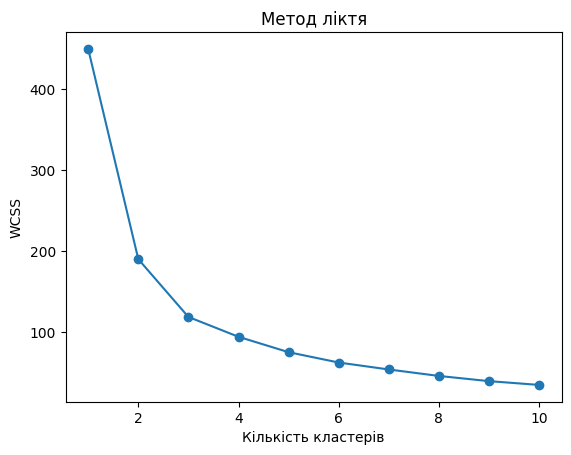

In [3]:
X_iris = iris_df.iloc[:, :3]

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_iris_scaled)
    wcss.append(model.inertia_)

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.title("Метод ліктя")
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

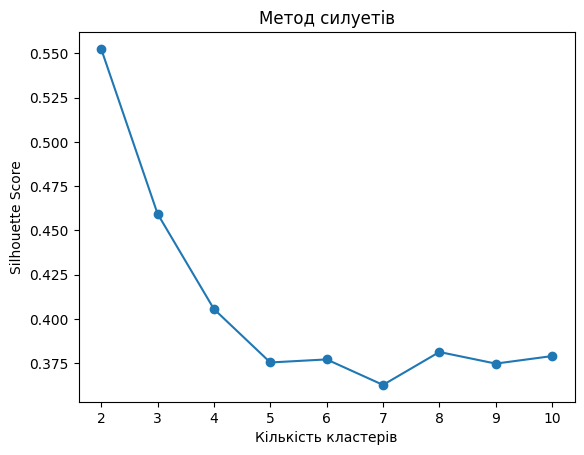

In [4]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        X_iris_scaled
    )

    silhouette_scores.append(
        silhouette_score(
            X_iris_scaled,
            labels
        )
    )

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Кількість кластерів")
plt.ylabel("Silhouette Score")
plt.title("Метод силуетів")
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

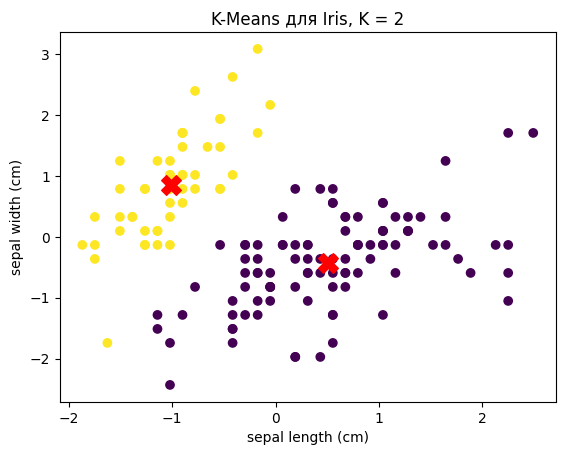

In [5]:
kmeans_iris = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

iris_labels = kmeans_iris.fit_predict(
    X_iris_scaled
)

centers = kmeans_iris.cluster_centers_

plt.scatter(
    X_iris_scaled[:, 0],
    X_iris_scaled[:, 1],
    c=iris_labels,
    cmap="viridis"
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=200,
    c="red"
)

plt.xlabel(X_iris.columns[0])
plt.ylabel(X_iris.columns[1])
plt.title("K-Means для Iris, K = 2")
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Метод ліктя показує найбільш суттєве зменшення WCSS при переході до 2–3 кластерів. Коефіцієнт силуета має найбільше значення при K = 2 (приблизно 0.552), тому для фінальної кластеризації було обрано два кластери. Таким чином, результати методів загалом узгоджуються, а метод силуетів більш однозначно вказує на K = 2.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [8]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [9]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [11]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [12]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [13]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
X = df.drop(
    columns=[
        "StudentID",
        "GradeClass"
    ]
)

y = df["GradeClass"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [17]:
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5]
}

rf_search = GridSearchCV(
    RandomForestClassifier(
        random_state=42
    ),
    rf_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

rf_search.fit(
    X_train_scaled,
    y_train
)

rf_pred = rf_search.predict(
    X_test_scaled
)

print(
    "Best params:",
    rf_search.best_params_
)

print(
    "CV Accuracy:",
    rf_search.best_score_
)

print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        rf_pred
    )
)

Best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
CV Accuracy: 0.9236736702527579
Test Accuracy: 0.9144050104384134


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [18]:
log_params = {
    "C": [0.01, 0.1, 1, 10],
    "penalty": ["l1", "l2"]
}

log_search = GridSearchCV(
    LogisticRegression(
        solver="saga",
        max_iter=5000,
        random_state=42
    ),
    log_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

log_search.fit(
    X_train_scaled,
    y_train
)

log_pred = log_search.predict(
    X_test_scaled
)

print(
    "Best params:",
    log_search.best_params_
)

print(
    "CV Accuracy:",
    log_search.best_score_
)

print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        log_pred
    )
)

Best params: {'C': 0.1, 'penalty': 'l1'}
CV Accuracy: 0.7961286618457206
Test Accuracy: 0.7661795407098121


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [19]:
svm_params = {
    "C": [0.1, 1, 10],
    "kernel": ["linear", "rbf"],
    "gamma": ["scale", "auto"]
}

svm_search = GridSearchCV(
    SVC(),
    svm_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

svm_search.fit(
    X_train_scaled,
    y_train
)

svm_pred = svm_search.predict(
    X_test_scaled
)

print(
    "Best params:",
    svm_search.best_params_
)

print(
    "CV Accuracy:",
    svm_search.best_score_
)

print(
    "Test Accuracy:",
    accuracy_score(
        y_test,
        svm_pred
    )
)

Best params: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
CV Accuracy: 0.8619947233879677
Test Accuracy: 0.8288100208768268


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [20]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Logistic Regression",
        "SVM"
    ],
    "CV Accuracy": [
        rf_search.best_score_,
        log_search.best_score_,
        svm_search.best_score_
    ],
    "Test Accuracy": [
        accuracy_score(
            y_test,
            rf_pred
        ),
        accuracy_score(
            y_test,
            log_pred
        ),
        accuracy_score(
            y_test,
            svm_pred
        )
    ]
})

comparison

,Model,CV Accuracy,Test Accuracy
0,Random Forest,0.923674,0.914405
1,Logistic Regression,0.796129,0.766180
2,SVM,0.861995,0.828810


In [21]:
searches = {
    "Random Forest": rf_search,
    "Logistic Regression": log_search,
    "SVM": svm_search
}

best_name = max(
    searches,
    key=lambda name:
        searches[name].best_score_
)

best_model = searches[
    best_name
].best_estimator_

best_pred = best_model.predict(
    X_test_scaled
)

print(
    "Найкраща модель:",
    best_name
)

print(
    classification_report(
        y_test,
        best_pred
    )
)

Найкраща модель: Random Forest
              precision    recall  f1-score   support

         0.0       0.83      0.45      0.59        22
         1.0       0.81      0.88      0.84        49
         2.0       0.94      0.87      0.90        85
         3.0       0.90      0.90      0.90        86
         4.0       0.94      0.99      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.82      0.84       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

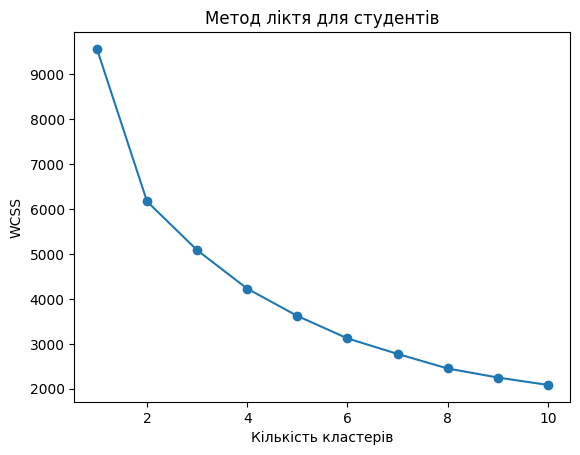

In [22]:
student_features = df[
    [
        "Age",
        "StudyTimeWeekly",
        "Absences",
        "GPA"
    ]
]

cluster_scaler = StandardScaler()

X_students = cluster_scaler.fit_transform(
    student_features
)

wcss_students = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_students)

    wcss_students.append(
        model.inertia_
    )

plt.plot(
    range(1, 11),
    wcss_students,
    marker="o"
)

plt.xlabel("Кількість кластерів")
plt.ylabel("WCSS")
plt.title("Метод ліктя для студентів")
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

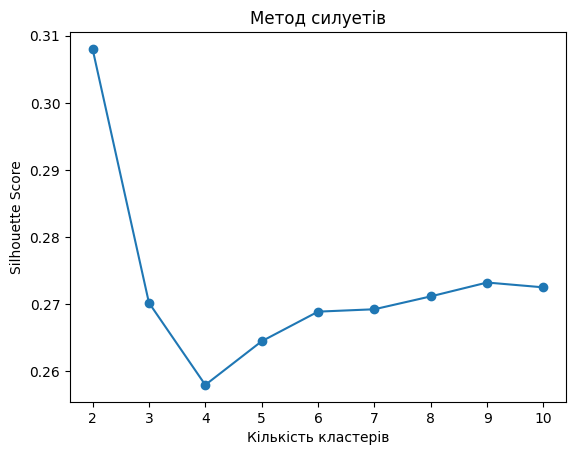

In [23]:
silhouette_students = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(
        X_students
    )

    silhouette_students.append(
        silhouette_score(
            X_students,
            labels
        )
    )

plt.plot(
    range(2, 11),
    silhouette_students,
    marker="o"
)

plt.xlabel("Кількість кластерів")
plt.ylabel("Silhouette Score")
plt.title("Метод силуетів")
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [24]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [25]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [26]:
X_pca_data = df.drop(
    columns=[
        "StudentID",
        "GradeClass"
    ]
)

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [27]:
pca_scaler = StandardScaler()

X_pca_scaled = pca_scaler.fit_transform(
    X_pca_data
)

pca_full = PCA()

pca_full.fit(
    X_pca_scaled
)

explained_variance = (
    pca_full.explained_variance_ratio_
)

explained_variance

array([0.15246911, 0.0861136 , 0.08267885, 0.08071826, 0.07864825,
       0.07793075, 0.0763079 , 0.07600434, 0.07440892, 0.0737979 ,
       0.07167781, 0.06746103, 0.00178329])

**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

In [28]:
pca_scaler = StandardScaler()

X_pca_scaled = pca_scaler.fit_transform(
    X_pca_data
)

pca_full = PCA()

pca_full.fit(
    X_pca_scaled
)

explained_variance = (
    pca_full.explained_variance_ratio_
)

explained_variance

array([0.15246911, 0.0861136 , 0.08267885, 0.08071826, 0.07864825,
       0.07793075, 0.0763079 , 0.07600434, 0.07440892, 0.0737979 ,
       0.07167781, 0.06746103, 0.00178329])

In [30]:
components = np.arange(
    1,
    len(explained_variance) + 1
)

knee = KneeLocator(
    components,
    explained_variance,
    curve="convex",
    direction="decreasing"
)

n_components = knee.knee

print(
    "Кількість компонент:",
    n_components
)

Кількість компонент: 2


**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

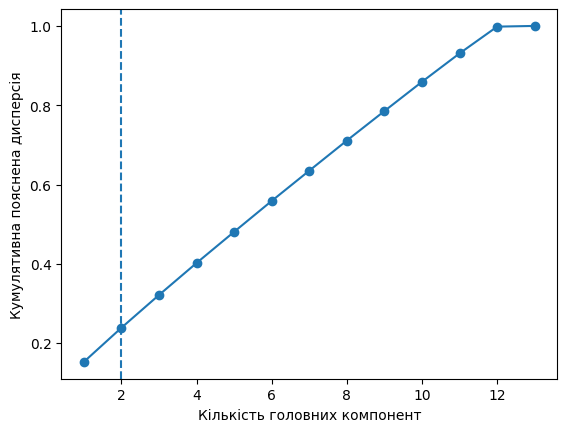

Пояснена дисперсія: 0.23858271308863227


In [31]:
cumulative_variance = np.cumsum(
    explained_variance
)

plt.plot(
    components,
    cumulative_variance,
    marker="o"
)

plt.axvline(
    n_components,
    linestyle="--"
)

plt.xlabel(
    "Кількість головних компонент"
)

plt.ylabel(
    "Кумулятивна пояснена дисперсія"
)

plt.show()

print(
    "Пояснена дисперсія:",
    cumulative_variance[
        n_components - 1
    ]
)

In [32]:
pca = PCA(
    n_components=n_components
)

X_pca = pca.fit_transform(
    X_pca_scaled
)

X_pca.shape

(2392, 2)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [33]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

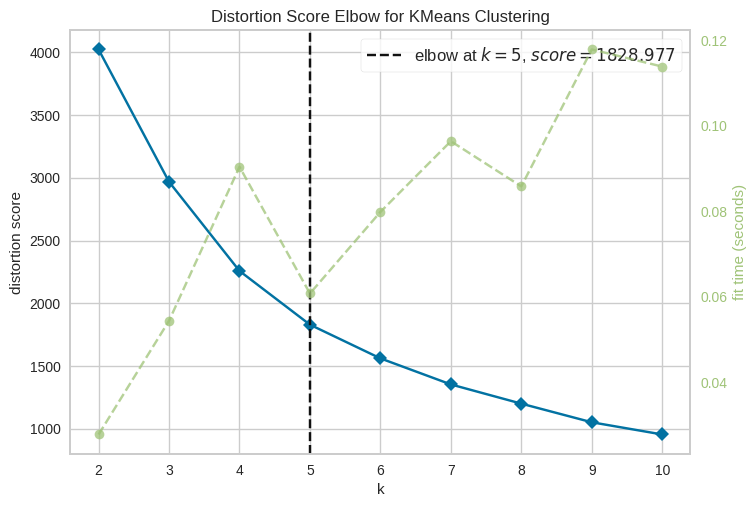

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [34]:
model = KMeans(
    random_state=42,
    n_init=10
)

visualizer = KElbowVisualizer(
    model,
    k=(2, 11)
)

visualizer.fit(
    X_pca
)

visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

У лабораторній роботі було досліджено методи класифікації та кластеризації даних. Для набору Iris метод силуетів показав найкращий результат при K = 2 із коефіцієнтом приблизно 0.552, а метод ліктя також вказав на невелику кількість кластерів.

Для даних студентів було порівняно Random Forest, Logistic Regression та SVM. Найкращою моделлю за CV Accuracy став Random Forest із результатом 0.924 та тестовою Accuracy 0.914. SVM отримав тестову Accuracy 0.829, а Logistic Regression — 0.766.

Під час кластеризації студентів за ознаками `Age`, `StudyTimeWeekly`, `Absences` та `GPA` найвище значення коефіцієнта силуета було отримано при K = 2. Додатково було виконано PCA для всіх ознак, крім `StudentID` та `GradeClass`. Метод KneeLocator обрав 2 головні компоненти, які разом пояснюють приблизно 23.86% загальної дисперсії. Після PCA метод ліктя через KElbowVisualizer визначив оптимальне значення K = 5.

Різниця в отриманій кількості кластерів пояснюється використанням різних наборів ознак і їх перетворенням через PCA. Класифікація та кластеризація вирішують різні задачі: при класифікації модель навчається прогнозувати відомий клас `GradeClass`, тоді як при кластеризації ця цільова змінна не використовується, а алгоритм самостійно шукає групи схожих студентів.